# Aquaporin sequences: cleaning, reshaping and exploring a protein family

**Module 02.2 · my implementation** — Seid Adem

In [02.1](../../01_apis_and_data_collection/implementation/01_uniprot_aquaporin_family.ipynb) I retrieved all 332
reviewed aquaporins (water-channel proteins) from UniProt and analysed their *annotations*. This notebook adds their
**sequences** and practises the 02.2 skills on them:

* **cleaning:** 150 inconsistent protein names → biologically meaningful subfamilies, without being misled by names
* **feature engineering** with my tested [`dsls.seq`](../../../src/dsls/seq.py) FASTA/k-mer utility
* **reshaping:** `melt` to long format, `groupby`, `pivot_table`
* **figures:** distributions, correlations and categorical comparisons, each followed by an interpretation

**Background.** Aquaporins form a pore of six membrane helices with two **NPA** motifs at its centre. Some are strictly
**water channels**; **aquaglyceroporins** (e.g. bacterial GlpF, human AQP3/7/9/10) also pass glycerol and other small
solutes. Plants have their own subfamilies (PIP, TIP, NIP, SIP, XIP).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA

from dsls.ebi_api import uniprot
from dsls.seq import AMINO_ACIDS, composition, find_motif, gravy, kmer_counts, parse_fasta
from dsls.uniprot import FIELDS, entry_to_record

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
QUERY = 'family:"MIP/aquaporin (TC 1.A.8) family" AND reviewed:true'  # same set as 02.1

## 1 · Load and join two API responses

Annotations come from the paginated JSON search (as in 02.1). Sequences come from UniProt's `stream` endpoint as FASTA,
parsed with `dsls.seq.parse_fasta`. The join uses `validate="one_to_one"`, so a duplicated or missing accession raises
an error instead of silently adding or dropping rows.

In [2]:
client = uniprot()
records = [
    entry_to_record(e)
    for page in client.paginate("uniprotkb/search", {"query": QUERY, "fields": FIELDS, "size": 100})
    for e in page.json()["results"]
]
annotations = pd.DataFrame(records)

fasta = client.get("uniprotkb/stream", {"query": QUERY, "format": "fasta"}, accept="text/plain").text
sequences = pd.DataFrame([{"accession": r.accession, "sequence": r.sequence} for r in parse_fasta(fasta)])

df = annotations.merge(sequences, on="accession", how="outer", validate="one_to_one", indicator=True)
assert (df["_merge"] == "both").all(), df["_merge"].value_counts()
df = df.drop(columns="_merge")
assert (df["sequence"].str.len() == df["length"]).all(), "FASTA length disagrees with annotated length"
print(
    f"{len(df)} proteins; {df['protein_name'].nunique()} distinct protein names; "
    f"non-standard residues in {(~df['sequence'].map(lambda s: set(s) <= set(AMINO_ACIDS))).sum()} sequences"
)

332 proteins; 150 distinct protein names; non-standard residues in 1 sequences


## 2 · Cleaning: from 150 names to subfamilies

Names are inconsistent ("Aquaporin-2", "Probable aquaporin PIP2-6", "Aquaporin PIP1-3/PIP1-4", "Glycerol uptake
facilitator protein", "Putative uncharacterized protein YLL053C" …). There is also a **trap**: fungi and other microbes
use numbered names ("Aquaporin-1", "Aquaporin-5") that are **not** homologues of mammalian AQP1/AQP5. Rules are
therefore applied *within* each lineage, and anything without a clear rule goes to an explicit "other" bucket. Section 7
tests this decision with sequence similarity.

In [3]:
PLANT = [
    (r"\bPIP\d|PIP-type", "PIP"),
    (r"\bTIP\d|TIP-type|\bRB7", "TIP"),
    (r"\bNIP\d|NIP-type|nodulin", "NIP"),
    (r"\bSIP\d", "SIP"),
    (r"\bXIP\d", "XIP"),
]
ANIMAL_NUMBERED = {
    0: "AQP0 (lens MIP)",
    **dict.fromkeys([1, 2, 4, 5, 6, 8], "AQP1/2/4/5/6/8"),
    **dict.fromkeys([3, 7, 9, 10], "AQP3/7/9/10"),
    **dict.fromkeys([11, 12], "AQP11/12"),
}
MICROBE = [
    (r"aquaporin Z|\baqpZ", "AqpZ"),
    (r"AqpM", "AqpM"),
    (r"glycerol|aquaglyceroporin|propanediol|\bglpF|lactic acid|\bFPS1", "GlpF-like"),
    (r"\bAQY\d", "AQY"),
]


def subfamily(name, gene, group):
    text = f"{name or ''} | {gene or ''}"
    if group == "Animals":
        if re.search(r"lens fiber major intrinsic", text, re.I):
            return ANIMAL_NUMBERED[0]
        m = re.search(r"aquaporin-(\d+)[A-Z]?\b|\|\s*AQP(\d+)[A-Z]?$", text, re.I)
        return ANIMAL_NUMBERED.get(int(m.group(1) or m.group(2)) if m else None, "Animal, other")
    rules, fallback = (PLANT, "Plant, other") if group == "Plants" else (MICROBE, "Microbial, other")
    return next((label for pattern, label in rules if re.search(pattern, text, re.I)), fallback)


df["subfamily"] = [
    subfamily(n, g, grp) for n, g, grp in zip(df["protein_name"], df["gene"], df["group"], strict=True)
]
# Expected selectivity from the literature, used only for well-characterised subfamilies
WATER = {"AQP0 (lens MIP)", "AQP1/2/4/5/6/8", "AqpZ", "PIP", "TIP", "AQY"}
GLYCEROL = {"AQP3/7/9/10", "GlpF-like"}
df["channel_type"] = np.select(
    [df["subfamily"].isin(WATER), df["subfamily"].isin(GLYCEROL)],
    ["water-selective", "aquaglyceroporin"],
    "other / unknown",
)
counts = df.pivot_table(index="subfamily", columns="group", values="accession", aggfunc="size", fill_value=0)
counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]

group,Animals,Archaea,Bacteria,Fungi,Other eukaryotes,Plants
subfamily,,,,,,
AQP1/2/4/5/6/8,49,0,0,0,0,0
PIP,0,0,0,0,0,44
"Microbial, other",0,0,1,36,5,0
GlpF-like,0,0,27,7,6,0
TIP,0,0,0,0,0,39
AqpZ,0,0,27,0,0,0
NIP,0,0,0,0,0,26
AQP3/7/9/10,19,0,0,0,0,0
AQP0 (lens MIP),10,0,0,0,0,0


In [4]:
numbered_microbes = df[
    df["subfamily"].eq("Microbial, other") & df["protein_name"].str.match(r"(Probable )?Aquaporin-\d")
]
print(
    f"{len(numbered_microbes)} non-animal proteins have numbered names like 'Aquaporin-5' and were NOT assigned to "
    f"mammalian subfamilies. Example of naming drift: "
    f"{df.loc[df['protein_name'].eq('Aquaporin-5') & df['gene'].eq('AQP6'), ['protein_name', 'gene', 'organism']].values.tolist()}"
)
print(
    f"In an explicit 'other' bucket: {df['subfamily'].str.contains('other').sum()} of {len(df)} "
    f"({df['subfamily'].str.contains('other').mean():.0%})"
)

18 non-animal proteins have numbered names like 'Aquaporin-5' and were NOT assigned to mammalian subfamilies. Example of naming drift: [['Aquaporin-5', 'AQP6', 'Botrytis cinerea (strain B05.10)']]
In an explicit 'other' bucket: 49 of 332 (15%)


## 3 · Feature engineering with `dsls.seq`

For each sequence: hydropathy (GRAVY, Kyte–Doolittle), charged, aromatic and glycine fractions, the spacing between the **two
NP[A/G/C/S/T] motifs** (measured only when a sequence has exactly two, so the pair is unambiguous), plus amino-acid composition. **Incomplete sequences are excluded** from everything
that depends on full length. That means UniProt's *Fragment* flag (14 sequences, see 02.1) **plus** a minimum length of
180 residues, because the flag misses a second kind of incompleteness (listed below).

In [5]:
MIN_LENGTH = 180  # far below any complete six-helix channel; catches split ORFs the Fragment flag misses
short = df[~df["is_fragment"] & (df["length"] < MIN_LENGTH)]
print(f"Not flagged as fragments but shorter than {MIN_LENGTH} aa: {len(short)}")
display(short[["accession", "protein_name", "gene", "organism", "length"]].sort_values("length"))
full = df[~df["is_fragment"] & (df["length"] >= MIN_LENGTH)].copy()
comp = pd.DataFrame([composition(s) for s in full["sequence"]], index=full.index)


def npa_spacing(seq):
    # only when there are exactly two NPA-like motifs; with 3+ hits the canonical pair is ambiguous
    hits = find_motif(seq, "NP[AGCST]")
    return hits[1] - hits[0] if len(hits) == 2 else np.nan


full = full.assign(
    gravy=full["sequence"].map(gravy),
    charged=comp[list("DEKR")].sum(axis=1),
    aromatic=comp[list("FWY")].sum(axis=1),
    glycine=comp["G"],
    npa_spacing=full["sequence"].map(npa_spacing),
)
n_hits = full["sequence"].map(lambda s: len(find_motif(s, "NP[AGCST]")))
print(
    f"{len(full)} complete sequences; NPA-like motifs per sequence: {n_hits.value_counts().sort_index().to_dict()}; "
    f"spacing measured for the {full['npa_spacing'].notna().sum()} with exactly two"
)
FEATURES = ["length", "gravy", "charged", "aromatic", "glycine", "n_transmembrane", "npa_spacing"]
full.groupby("channel_type")[FEATURES].median().round(3)

Not flagged as fragments but shorter than 180 aa: 10


,accession,protein_name,gene,organism,length
19,A7A0K8,Aquaporin-like protein 2,AQY2-2,Saccharomyces cerevisiae (strain YJM789),149
31,B3LTC5,Aquaporin-like protein 2,AQY2-2,Saccharomyces cerevisiae (strain RM11-1a),149
35,C7GNE3,Aquaporin-like protein 2,AQY2-2,Saccharomyces cerevisiae (strain JAY291),149
37,C8ZCS3,Aquaporin-like protein 2,AQY2-2,Saccharomyces cerevisiae (strain Lalvin EC1118...,149
97,P0CD90,Aquaporin-like protein 2,AQY2,Saccharomyces cerevisiae (strain ATCC 204508 /...,149
18,A7A0K7,Putative uncharacterized protein SCY_3531,None,Saccharomyces cerevisiae (strain YJM789),152
30,B3LTC4,Putative uncharacterized protein SCRG_04940,None,Saccharomyces cerevisiae (strain RM11-1a),152
34,C7GNE2,Putative uncharacterized protein C1Q_01798,None,Saccharomyces cerevisiae (strain JAY291),152
36,C8ZCS2,Putative uncharacterized protein EC1118_1L10_0...,None,Saccharomyces cerevisiae (strain Lalvin EC1118...,152
100,P0CD98,Putative uncharacterized protein YLL053C,None,Saccharomyces cerevisiae (strain ATCC 204508 /...,152


308 complete sequences; NPA-like motifs per sequence: {0: 4, 1: 26, 2: 254, 3: 22, 4: 1, 5: 1}; spacing measured for the 254 with exactly two


,length,gravy,charged,aromatic,glycine,n_transmembrane,npa_spacing
channel_type,,,,,,,
aquaglyceroporin,281.0,0.608,0.114,0.117,0.114,6.0,132.0
other / unknown,286.0,0.518,0.119,0.108,0.095,6.0,117.0
water-selective,265.5,0.600,0.114,0.110,0.116,6.0,116.0


## 4 · Reshaping: which residues distinguish the subfamilies?

Composition is **wide** (one column per amino acid). `melt` makes it **long** (one row per protein × residue), which is
what `groupby` and seaborn expect. A `pivot_table` then gives a subfamily × residue matrix. Values are z-scored per
residue, so the heatmap shows *relative* enrichment rather than the residues that are simply common everywhere.

wide (308, 20) → long (6160, 4)


residue,C,G,K,R,W,Y
subfamily,,,,,,
PIP,1.4,11.6,3.7,3.6,1.8,4.0
TIP,0.6,13.1,1.5,2.2,1.6,2.9
NIP,1.4,9.6,2.5,3.5,1.2,2.5
SIP,0.8,8.6,4.8,2.6,2.7,2.8
AQP0 (lens MIP),0.8,10.5,1.1,4.9,1.9,2.9
AQP1/2/4/5/6/8,1.7,9.5,3.0,3.8,1.9,2.3
AqpZ,0.9,14.3,1.8,1.9,2.1,2.4
AQP3/7/9/10,1.4,10.7,2.7,3.4,2.0,3.4
AQP11/12,3.3,6.3,2.3,3.8,1.3,2.7


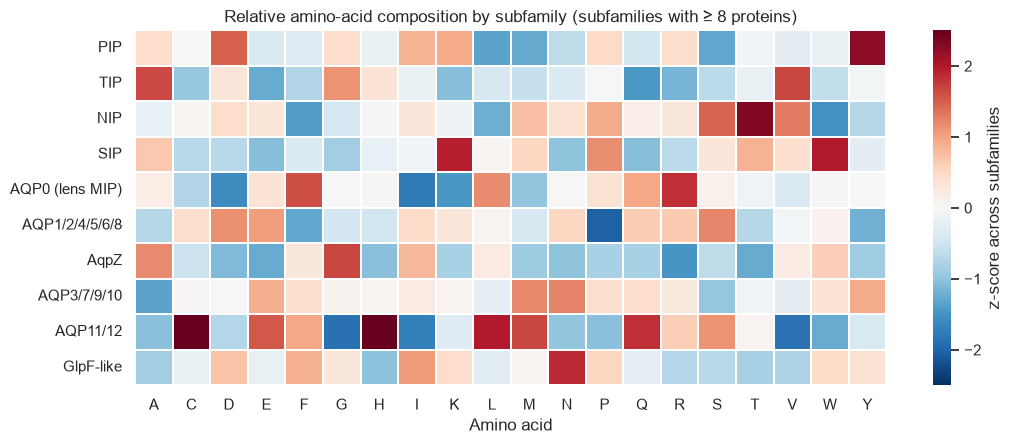

In [6]:
MAIN = (
    full["subfamily"]
    .value_counts()
    .loc[lambda s: s >= 8]
    .index.drop([s for s in full["subfamily"].unique() if "other" in s], errors="ignore")
)
long = comp.join(full[["accession", "subfamily"]]).melt(
    id_vars=["accession", "subfamily"], var_name="residue", value_name="fraction"
)
print(f"wide {comp.shape} → long {long.shape}")
profile = long[long["subfamily"].isin(MAIN)].pivot_table(
    index="subfamily", columns="residue", values="fraction", aggfunc="mean"
)
z = (profile - profile.mean()) / profile.std()
order = [
    "PIP",
    "TIP",
    "NIP",
    "SIP",
    "AQP0 (lens MIP)",
    "AQP1/2/4/5/6/8",
    "AqpZ",
    "AQY",
    "AQP3/7/9/10",
    "AQP11/12",
    "GlpF-like",
]
z = z.reindex([o for o in order if o in z.index])

fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(
    z,
    cmap="RdBu_r",
    center=0,
    vmin=-2.5,
    vmax=2.5,
    ax=ax,
    cbar_kws={"label": "z-score across subfamilies"},
    linewidths=0.3,
)
ax.set(
    xlabel="Amino acid",
    ylabel="",
    title="Relative amino-acid composition by subfamily (subfamilies with ≥ 8 proteins)",
)
fig.tight_layout()
fig.savefig(FIGURES / "01_composition_heatmap.png", dpi=150)
profile.mul(100).round(1).loc[z.index, ["C", "G", "K", "R", "W", "Y"]]

## 5 · Distributions: length, hydropathy and the NPA spacing

length          gravy       npa_spacing       
                median     std median   std      median    std
subfamily                                                     
PIP              287.0    3.44   0.46  0.08       121.0   0.23
TIP              251.0    6.26   0.82  0.13       114.0   1.99
NIP              294.0   13.26   0.49  0.11       112.0   3.20
SIP              244.0    4.36   0.70  0.12       115.0   1.30
AQP0 (lens MIP)  263.0    0.32   0.58  0.03       116.0   0.00
AQP1/2/4/5/6/8   271.0   27.49   0.52  0.16       116.0   4.82
AqpZ             231.0    5.75   0.94  0.09       122.0   0.86
AQP3/7/9/10      295.0   32.74   0.53  0.17       132.0  35.68
AQP11/12         271.5   11.67   0.62  0.15       117.0   1.07
GlpF-like        264.0  122.37   0.72  0.39       130.0  19.89

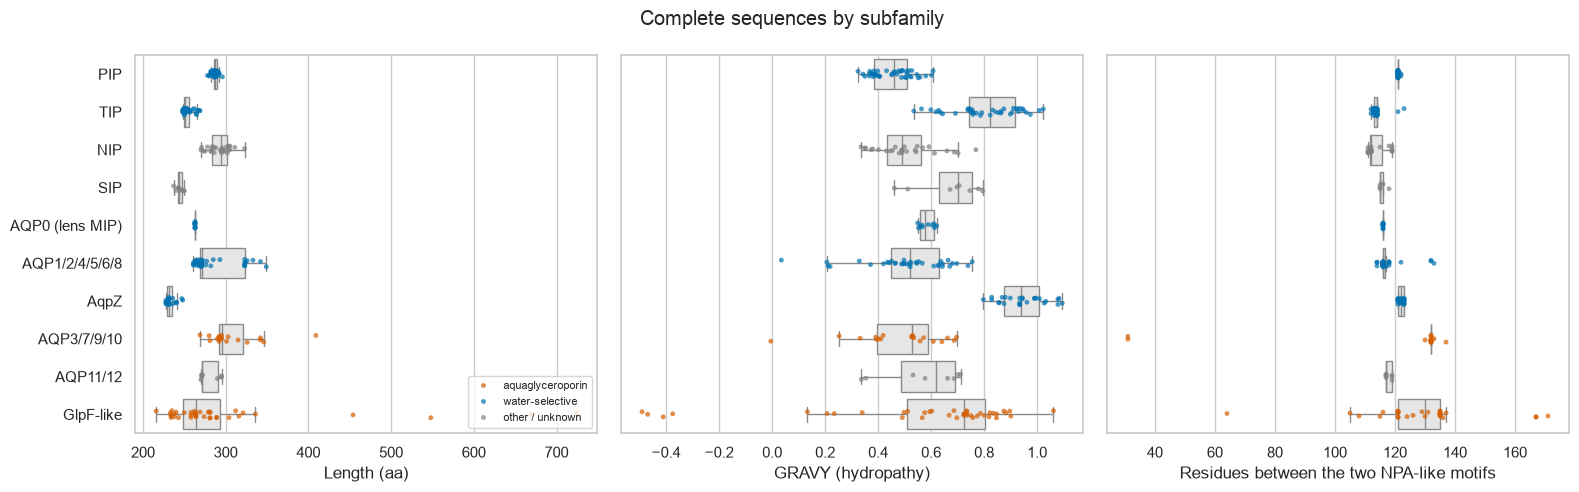

In [7]:
order_main = [o for o in order if o in MAIN]
sub = full[full["subfamily"].isin(order_main)]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, col, label in zip(
    axes,
    ["length", "gravy", "npa_spacing"],
    ["Length (aa)", "GRAVY (hydropathy)", "Residues between the two NPA-like motifs"],
    strict=True,
):
    sns.boxplot(data=sub, y="subfamily", x=col, order=order_main, ax=ax, color="0.9", fliersize=0)
    sns.stripplot(
        data=sub,
        y="subfamily",
        x=col,
        order=order_main,
        ax=ax,
        hue="channel_type",
        size=3.5,
        alpha=0.7,
        palette={"water-selective": "#0072B2", "aquaglyceroporin": "#D55E00", "other / unknown": "0.5"},
        legend=ax is axes[0],
    )
    ax.set(xlabel=label, ylabel="")
axes[0].legend(title="", fontsize=8, loc="lower right")
fig.suptitle("Complete sequences by subfamily")
fig.tight_layout()
fig.savefig(FIGURES / "02_distributions.png", dpi=150)
sub.groupby("subfamily")[["length", "gravy", "npa_spacing"]].agg(["median", "std"]).round(2).loc[order_main]

## 6 · Correlations and the water-vs-glycerol comparison

Spearman correlations (rank-based, robust to the skewed length distribution) between the sequence features, then a
**categorical comparison** of water-selective channels and aquaglyceroporins using Mann–Whitney U tests. Effect sizes are
reported as the rank-biserial correlation, so the answer isn't just a *p*-value.

Strongest feature correlations (Spearman ρ): {('length', 'gravy'): -0.86, ('gravy', 'charged'): -0.82, ('length', 'charged'): 0.7, ('gravy', 'glycine'): 0.52}
water-selective n = 160, aquaglyceroporin n = 59


,water_median,glycerol_median,rank_biserial,p_value,p_bonferroni
feature,,,,,
length,265.5000,281.0000,0.2829,0.0013,0.0080
gravy,0.6003,0.6082,-0.0890,0.3133,1.0000
charged,0.1135,0.1139,0.0413,0.6401,1.0000
aromatic,0.1096,0.1174,0.3352,0.0001,0.0009
glycine,0.1163,0.1139,-0.1950,0.0270,0.1620
npa_spacing,116.0000,132.0000,0.6191,0.0000,0.0000


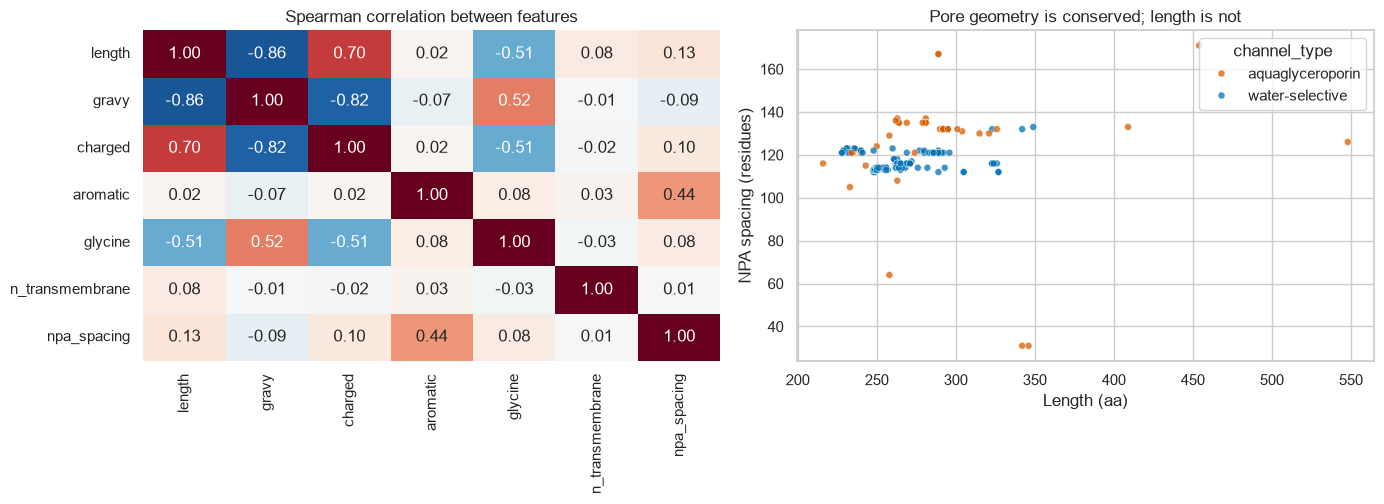

In [8]:
corr = full[FEATURES].corr(method="spearman")
pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
)
print("Strongest feature correlations (Spearman ρ):", pairs.head(4).round(2).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Spearman correlation between features")
two = full[full["channel_type"] != "other / unknown"]
sns.scatterplot(
    data=two,
    x="length",
    y="npa_spacing",
    hue="channel_type",
    ax=axes[1],
    s=25,
    alpha=0.75,
    palette={"water-selective": "#0072B2", "aquaglyceroporin": "#D55E00"},
)
axes[1].set(
    xlabel="Length (aa)", ylabel="NPA spacing (residues)", title="Pore geometry is conserved; length is not"
)
fig.tight_layout()
fig.savefig(FIGURES / "03_correlations.png", dpi=150)

rows = []
for col in ["length", "gravy", "charged", "aromatic", "glycine", "npa_spacing"]:
    w = two.loc[two["channel_type"] == "water-selective", col].dropna()
    g = two.loc[two["channel_type"] == "aquaglyceroporin", col].dropna()
    u, p = stats.mannwhitneyu(g, w, alternative="two-sided")
    rows.append(
        {
            "feature": col,
            "water_median": w.median(),
            "glycerol_median": g.median(),
            "rank_biserial": 2 * u / (len(g) * len(w)) - 1,
            "p_value": p,
        }
    )
tests = pd.DataFrame(rows).set_index("feature")
tests["p_bonferroni"] = (tests["p_value"] * len(tests)).clip(upper=1)
print(
    f"water-selective n = {(two['channel_type'] == 'water-selective').sum()}, "
    f"aquaglyceroporin n = {(two['channel_type'] == 'aquaglyceroporin').sum()}"
)
tests.round(4)

## 7 · Do k-mers recover the subfamilies, and was the cleaning right?

Each sequence becomes a vector of **400 dipeptide (2-mer) frequencies** using `kmer_counts`. No alignment and no names are
used. PCA projects these vectors to 2-D. The cleaning decision is then tested directly: for each numbered non-animal
"Aquaporin-n", which subfamily does its **nearest neighbour** (cosine similarity in k-mer space) belong to?

In [9]:
DIPEPTIDES = [a + b for a in AMINO_ACIDS for b in AMINO_ACIDS]
K = pd.DataFrame([kmer_counts(s, 2, AMINO_ACIDS) for s in full["sequence"]], index=full.index)
K = K.reindex(columns=DIPEPTIDES, fill_value=0).fillna(0)
K = K.div(K.sum(axis=1), axis=0)

pca = PCA(n_components=2, random_state=0)
pcs = pd.DataFrame(pca.fit_transform(K - K.mean()), index=K.index, columns=["PC1", "PC2"]).join(
    full[["subfamily", "group"]]
)
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_.sum():.0%} of dipeptide variance")

# nearest neighbour (cosine) for every complete sequence
unit = K.to_numpy() / np.linalg.norm(K.to_numpy(), axis=1, keepdims=True)
sim = unit @ unit.T
np.fill_diagonal(sim, -1)
nn = pd.Series(full["subfamily"].to_numpy()[sim.argmax(axis=1)], index=full.index, name="nn_subfamily")
known = full["subfamily"].isin(MAIN)
nn_acc = (nn[known] == full.loc[known, "subfamily"]).mean()
print(
    f"Leave-one-out nearest-neighbour agreement with the cleaned subfamily labels: {nn_acc:.0%} "
    f"({known.sum()} proteins in the main subfamilies)"
)

fungal_numbered = full.index[
    full["subfamily"].eq("Microbial, other") & full["protein_name"].str.match(r"(Probable )?Aquaporin-\d")
]
print(
    "Nearest neighbours of numbered non-animal 'Aquaporin-n' proteins:",
    nn.loc[fungal_numbered].value_counts().to_dict(),
)

PC1 + PC2 explain 15% of dipeptide variance
Leave-one-out nearest-neighbour agreement with the cleaned subfamily labels: 93% (256 proteins in the main subfamilies)
Nearest neighbours of numbered non-animal 'Aquaporin-n' proteins: {'Microbial, other': 13, 'AQP1/2/4/5/6/8': 2, 'TIP': 1, 'Animal, other': 1, 'AQY': 1}


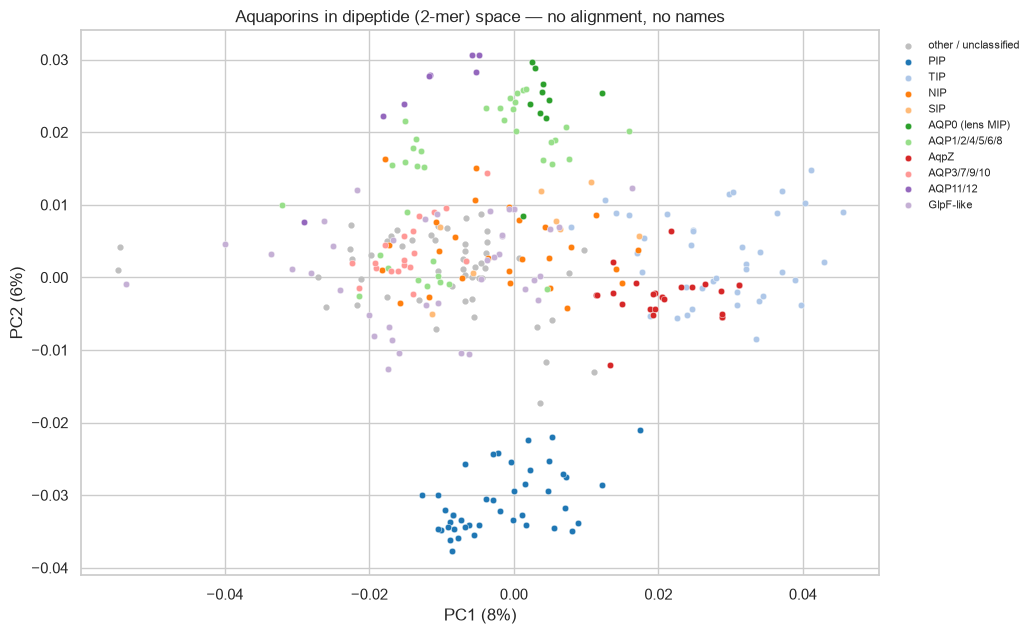

In [10]:
palette = dict(zip(order_main, sns.color_palette("tab20", len(order_main)), strict=True))
fig, ax = plt.subplots(figsize=(10.5, 6.5))
other = pcs[~pcs["subfamily"].isin(order_main)]
ax.scatter(other["PC1"], other["PC2"], s=12, color="0.75", label="other / unclassified")
for s in order_main:
    d = pcs[pcs["subfamily"] == s]
    ax.scatter(d["PC1"], d["PC2"], s=22, color=palette[s], label=s, edgecolor="white", linewidth=0.3)
ax.set(
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
    title="Aquaporins in dipeptide (2-mer) space — no alignment, no names",
)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "04_kmer_pca.png", dpi=150)

## 8 · Findings

**Cleaning was most of the work, and three of its decisions changed the results.**
* **Names can't be trusted across kingdoms.** 18 fungal and protist proteins are called "Aquaporin-1/2/5/…", but they
  aren't homologues of mammalian AQP1/2/5. One is even named "Aquaporin-5" with the gene *AQP6*. The sequence check in
  section 7 supports keeping them separate: 13 of the 18 have their nearest k-mer neighbour among other non-animal
  aquaporins, and only 2 among mammalian-type AQP1/2/4/5/6/8.
* **"Not a fragment" doesn't mean "complete".** Ten *S. cerevisiae* entries of 149–152 aa are the two halves of one
  *AQY2* gene, split by an 11-bp frameshift deletion (documented in their UniProt caution notes). UniProt doesn't flag
  them as fragments, so they passed the first filter and showed up as implausible AQY length outliers.
  A minimum-length rule removes them, and they're listed explicitly.
* **Motif counting needs a defined rule.** 24 sequences have three or more NPA-like matches. Measuring "first to last"
  mixed in spurious matches and inflated the spread (SD up to 70 residues in GlpF-like). Measuring only when there are
  exactly two matches brings the SD within each water-channel subfamily down to ≤ 5 residues.

**Reshaping (melt → groupby → pivot) shows each subfamily's chemical signature (figure 1).** AqpZ and TIPs are the most
glycine-rich (14.3 %, 13.1 %) and the most hydrophobic (median GRAVY 0.94 and 0.82). PIPs are the most tyrosine-rich
(4.0 %). AQP0 is arginine-rich and lysine-poor (4.9 % vs 1.1 %). The superaquaporins AQP11/12 stand out with more
cysteine (3.3 %) and the least glycine (6.3 %).

**Distributions (figure 2).** Length varies within the family (median 231 aa in AqpZ to 295 aa in AQP3/7/9/10), but
the **distance between the two NPA motifs is almost fixed within each subfamily**: PIP 121 ± 0.2, AQP0 116 ± 0, AqpZ
122 ± 0.9. The pore's core geometry is conserved, and length differences sit elsewhere in the protein.

**Correlations (figure 3).** The strongest relationship is **length vs hydropathy (ρ = −0.86)**, together with length vs
charged-residue fraction (ρ = +0.70). Longer aquaporins are *less* hydrophobic overall. This fits the six-helix core
being roughly constant, so extra length comes mostly from charged, soluble regions (termini and loops) that dilute
hydrophobicity. That's an inference from composition, not from mapped domains.

**Water channels vs aquaglyceroporins (Mann–Whitney, 160 vs 59 proteins).** The clearest difference is the **NPA
spacing: 132 vs 116 residues (rank-biserial r = 0.62, Bonferroni p < 0.001)**. Aquaglyceroporins carry about 16
extra residues between the two pore motifs. They are also longer (281 vs 266 aa, r = 0.28) and slightly richer in
aromatic residues (11.7 % vs 11.0 %, r = 0.34). Overall hydropathy and charge don't differ. These are related proteins,
not independent samples, so the p-values are indicative only.

**k-mers alone recover the curated subfamilies (figure 4).** Using only dipeptide frequencies (no alignment, no names),
each protein's nearest neighbour belongs to the same cleaned subfamily **93 % of the time** (256 proteins). The 2-D
PCA keeps only 15 % of the variance, yet PIPs separate completely, and TIPs/AqpZ and AQP0/AQP1-type proteins form
distinct regions. A crude, alignment-free representation is enough to check name-based curation.

## Reproducibility notes
* **Data:** UniProtKB/Swiss-Prot, query `family:"MIP/aquaporin (TC 1.A.8) family" AND reviewed:true`, cached in
  `data/raw/api_cache/uniprot/` with the release in the response headers (the same set as 02.1).
* **Code:** sequence functions are in `src/dsls/seq.py`, unit-tested in `tests/test_seq.py` (FASTA edge cases,
  overlapping motifs, k-mer filtering). The subfamily rules are written out in full in section 2.
* **Statistics:** Mann–Whitney U with Bonferroni correction across six features. These are exploratory comparisons on
  related proteins, which are not independent samples (phylogeny), so *p*-values are indicative only.
* *UniProt data: [CC BY 4.0](https://www.uniprot.org/help/license).*